# 

## Celda 0: entorno

In [1]:
# recarga los .py de src/ al editarlos, sin reiniciar el kernel
%reload_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import pandas as pd

# las rutas son relativas, asi que solo funcionan desde notebooks/
if not Path("../src/geo_download.py").exists():
    raise FileNotFoundError(
        "No se encontró ../src/. Solución: abre este notebook desde la "
        "carpeta notebooks/ del proyecto."
    )

sys.path.insert(0, "../src")

RAW = Path("../data/raw")
PROC = Path("../data/processed")
TABLES = Path("../results/tables")
FIGURES = Path("../results/figures")
for folder in (RAW, PROC, TABLES, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)
print("Entorno listo")

Entorno listo


## Celda 1: consultar la serie

In [2]:
from Bio import Entrez
import geo_download as geo

# NCBI pide un correo para contactar a quien sature el servicio
Entrez.email = "andcoral@lcg.unam.mx"

ACCESSION = "GSE103441"
try:
    summary = geo.get_gse_summary(ACCESSION)
    print(summary["Accession"], "|", summary["title"])
    print("N muestras:", int(summary["n_samples"]))
except (ValueError, ConnectionError) as error:
    # sin NCBI se puede seguir con lo que ya esta guardado en data/
    summary = None
    print(f"Error: {error}\nSe usarán los archivos locales de data/.")

GSE103441 | In planta bacterial RNA-Seq with bacterial isolation.
N muestras: 114


## Celda 2: BioProject y tabla de muestras

In [3]:
SAMPLES_CSV = PROC / "GEO_samples.csv"

if summary is not None:
    print("BioProject:", geo.validate_bioproject(summary))
    samples = geo.get_samples_table(summary)
    samples.to_csv(SAMPLES_CSV, index=False)
elif SAMPLES_CSV.exists():
    samples = pd.read_csv(SAMPLES_CSV)
    print(f"Sin conexión: tabla cargada de {SAMPLES_CSV}")
else:
    raise FileNotFoundError(
        f"Sin conexión y sin {SAMPLES_CSV}. Solución: conéctate y "
        "ejecuta desde la celda 1."
    )
samples

BioProject: {'PRJNA401856': True}


,gsm,title
0,GSM2771404,Pto-AvrRpt2_col_A25
1,GSM2771470,Pto-AvrRpt2_KB_A81
2,GSM2771424,Pto-AvrRpt2_col_A47
3,GSM2771407,Pto_col_A26
4,GSM2771444,Pto_col_A58
...,...,...
109,GSM2771438,Pto_col_chitin_A54
110,GSM2771418,Pto-AvrRpt2_sid2_A42
111,GSM2771455,Pto-AvrRpt2_pad4_A66
112,GSM2771375,Pto_pad4_A17


## Celda 3: archivos suplementarios

In [4]:
suppl_url, files = None, []
if summary is not None:
    try:
        suppl_url, files = geo.list_supplementary_files(summary)
        print(suppl_url)
        for file_name in files:
            print(" -", file_name)
    except (FileNotFoundError, ConnectionError) as error:
        print(f"Error: {error}\nSe usará la copia local de la matriz.")

https://ftp.ncbi.nlm.nih.gov/geo/series/GSE103nnn/GSE103441/suppl/
 - GSE103441_count.txt.gz


## Celda 4: descargar y validar la matriz

In [5]:
FILE_NAME = "GSE103441_count.txt.gz"

# un nombre mal escrito daria un 404 poco claro al descargar
if files and FILE_NAME not in files:
    raise FileNotFoundError(f"{FILE_NAME} no está. Disponibles: {files}")

if suppl_url is not None:
    path = geo.download_file(suppl_url, FILE_NAME, RAW)
elif (RAW / FILE_NAME).exists():
    path = RAW / FILE_NAME
    print(f"Sin conexión: se usa {path}")
else:
    raise FileNotFoundError(
        f"Sin conexión y sin {RAW / FILE_NAME}. Solución: conéctate y "
        "ejecuta desde la celda 1."
    )
count_matrix = geo.validate_count_matrix(path)
count_matrix.iloc[:5, :6]

Ya existe: ..\data\raw\GSE103441_count.txt.gz
Genes x muestras: (5618, 114)
¿Todos enteros? True
NaN: 0 | IDs duplicados: 0


,Pto_col_mock_A22,Pto_col_mock_A23,Pto_col_mock_A52,Pto_col_mock_A53,Pto_col_mock_A54,Pto_col_chitin_A52
PSPTOA0002,0,0,0,0,0,0
PSPTOA0004,0,0,0,0,0,0
PSPTOA0005,0,0,0,0,0,0
PSPTOA0007,0,0,0,0,3,0
PSPTOA0008,0,0,0,0,0,0


## Celda 5: seleccionar muestras

In [6]:
import data_prep as prep

selection = prep.select_samples(count_matrix.columns)
print(selection["condition"].value_counts())
# se imprimen para revisar a ojo que no se cuele un pretratamiento
print(selection[selection["condition"] != "exclude"].to_string())

# Dataset S1 del artículo: 13 de planta y 2 de cultivo
prep.verify_selection(selection, {"plant": 13, "culture": 2})

condition
exclude    99
plant      13
culture     2
Name: count, dtype: int64
          sample condition
11   Pto_col_A13     plant
12   Pto_col_A14     plant
13   Pto_col_A15     plant
14   Pto_col_A17     plant
15   Pto_col_A25     plant
16   Pto_col_A26     plant
17   Pto_col_A42     plant
18   Pto_col_A66     plant
19   Pto_col_A57     plant
20   Pto_col_A58     plant
21   Pto_col_A59     plant
88    Pto_KB_A81   culture
89    Pto_KB_A83   culture
106  Pto_col_A71     plant
110  Pto_col_A74     plant
Selección verificada: {'plant': 13, 'culture': 2}


## Celda 6: separar y validar IDs de gen

In [7]:
# locus_key (sin guion bajo) es la clave para unir con GenBank
ids_table = prep.split_id_description(count_matrix.index)
prep.validate_gene_ids(ids_table)

# random_state fijo para ver siempre las mismas filas
ids_table.sample(6, random_state=1)

Locus tag con formato PSPTO: 5618 de 5618
Cromosoma: 5481 | Plásmido A: 67 | Plásmido B: 70
Genes con descripción: 5552
Locus tag repetidos: 0


,original_id,locus_tag,description,locus_key
1840,PSPTO_1819-major facilitator superfamily trans...,PSPTO_1819,major facilitator superfamily transporter,PSPTO1819
3198,"PSPTO_3221-ISPsy5, Orf1",PSPTO_3221,"ISPsy5, Orf1",PSPTO3221
5506,PSPTO_5600-F0F1 ATP synthase subunit gamma,PSPTO_5600,F0F1 ATP synthase subunit gamma,PSPTO5600
200,PSPTO_0139-hypothetical protein,PSPTO_0139,hypothetical protein,PSPTO0139
5152,PSPTO_5231-oxidoreductase zinc-binding protein,PSPTO_5231,oxidoreductase zinc-binding protein,PSPTO5231
4307,PSPTO_4361-chromosome initiation inhibitor,PSPTO_4361,chromosome initiation inhibitor,PSPTO4361


## Celda 7: limpiar y filtrar

In [8]:
# counts_raw (sin filtrar) se conserva para revisar las muestras en la celda 14
counts_raw, meta = prep.build_count_table(count_matrix, ids_table, selection)
counts = prep.filter_low_counts(counts_raw, min_cpm=1, min_samples=2)
counts.iloc[:5, :5]

Muestras: 15 | Genes antes del filtro: 5618
Genes que pasan el filtro: 5394 de 5618


,Pto_col_A13,Pto_col_A14,Pto_col_A15,Pto_col_A17,Pto_col_A25
PSPTO0001,4167,5779,2727,3160,2859
PSPTO0002,1272,1462,851,1348,935
PSPTO0003,859,1341,580,914,497
PSPTO0004,2645,3430,2186,3062,2109
PSPTO0005,98,184,81,221,128


## Celda 8: añadir GSM y guardar

In [9]:
# el GSM permite citar cada muestra en el informe
meta = prep.add_gsm(meta, samples)
counts.to_csv(PROC / "counts_filtered.csv")
meta.to_csv(PROC / "sample_metadata.csv")
print(counts.shape, "|", meta["condition"].value_counts().to_dict())
meta

(5394, 15) | {'plant': 13, 'culture': 2}


,condition,gsm
sample,,
Pto_col_A13,plant,GSM2771365
Pto_col_A14,plant,GSM2771381
Pto_col_A15,plant,GSM2771389
Pto_col_A17,plant,GSM2771373
Pto_col_A25,plant,GSM2771401
Pto_col_A26,plant,GSM2771407
Pto_col_A42,plant,GSM2771413
Pto_col_A66,plant,GSM2771451
Pto_col_A57,plant,GSM2771440


## Celda 9: validar accesos del genoma

In [10]:
import annotation as ann

# sin version: NCBI devuelve la vigente
ACCESSIONS = ["NC_004578", "NC_004633", "NC_004632"]

try:
    accessions = ann.validate_nuccore_accessions(ACCESSIONS)
except (ValueError, ConnectionError) as error:
    # los .gb ya descargados bastan para seguir sin conexion
    accessions = [
        gb.stem for acc in ACCESSIONS for gb in RAW.glob(f"{acc}.*.gb")
    ]
    print(f"Error: {error}\nSe usarán los GenBank locales.")
    if len(accessions) != len(ACCESSIONS):
        raise FileNotFoundError(
            f"Solo hay {len(accessions)} de {len(ACCESSIONS)} GenBank "
            "locales. Solución: conéctate y vuelve a ejecutar."
        ) from error
print(accessions)

NC_004578.1 | Pseudomonas syringae pv. tomato str. DC3000, complete sequence
NC_004633.1 | Pseudomonas syringae pv. tomato str. DC3000 plasmid pDC3000A, complete sequence
NC_004632.1 | Pseudomonas syringae pv. tomato str. DC3000 plasmid pDC3000B, complete sequence
['NC_004578.1', 'NC_004633.1', 'NC_004632.1']


## Celda 10: descargar los GenBank

In [11]:
# los que ya existen en data/raw/ no se descargan otra vez
genbank_paths = [ann.download_genbank(acc, RAW) for acc in accessions]

Ya existe: ..\data\raw\NC_004578.1.gb
  NC_004578.1: 6397126 pb, 5731 CDS
Ya existe: ..\data\raw\NC_004633.1.gb
  NC_004633.1: 73661 pb, 76 CDS
Ya existe: ..\data\raw\NC_004632.1.gb
  NC_004632.1: 67473 pb, 78 CDS


## Celda 11: extraer y unir con la matriz

In [12]:
annotation_gb = ann.extract_cds(genbank_paths)
print(annotation_gb.shape)
print(annotation_gb.head(3).T)

# solo se anotan los genes que sobrevivieron al filtro de expresion
filtered_ids = ids_table[ids_table["locus_key"].isin(counts.index)]
print("Genes a anotar:", len(filtered_ids))

annotation = ann.merge_with_matrix(annotation_gb, filtered_ids)

# la tabla completa sirve para consultar los CDS que no estan en la matriz
annotation_gb.to_csv(PROC / "genbank_annotation_DC3000.csv", index=False)

(5885, 9)
                                                               0  \
locus_tag                                          PSPTO_RS00005   
old_locus_tag                                          PSPTO0001   
gene                                                        dnaA   
product           chromosomal replication initiator protein DnaA   
note           Derived by automated computational analysis us...   
replicon                                             NC_004578.1   
start                                                        339   
end                                                         1874   
strand                                                         1   

                                                               1  \
locus_tag                                          PSPTO_RS00010   
old_locus_tag                                          PSPTO0002   
gene                                                        dnaN   
product                          DNA 

## Celda 12: combinar y guardar la anotacion final

In [13]:
final_annotation = ann.combine_annotation(annotation, filtered_ids)

# Q2 y Q3 se unen por locus_key, asi que deben ser los mismos genes
if set(final_annotation.index) != set(counts.index):
    raise ValueError("La anotación final no cubre los genes de counts")

n_hypothetical = (
    final_annotation["final_product"]
    .str.contains("hypothetical", case=False, na=False)
    .sum()
)
print("Productos 'hypothetical' (anotación final):", int(n_hypothetical))

# Int64 admite vacios; con float, pandas guardaria 339.0 en vez de 339
for column in ["start", "end", "strand"]:
    final_annotation[column] = final_annotation[column].astype("Int64")

final_annotation.to_csv(PROC / "final_annotation.csv")
final_annotation.head()

Genes con ambas fuentes: 5152 | descripción idéntica: 992
Fuente del producto final: {'GenBank (RefSeq)': 5152, 'Count matrix': 242}
Genes sin descripción en ninguna fuente: 0
Productos 'hypothetical' (anotación final): 525


,locus_tag_matrix,description_matrix,locus_tag_refseq,gene,product_genbank,note_genbank,replicon,start,end,strand,final_product,source
locus_key,,,,,,,,,,,,
PSPTO0001,PSPTO_0001,chromosomal replication initiation protein,PSPTO_RS00005,dnaA,chromosomal replication initiator protein DnaA,Derived by automated computational analysis us...,NC_004578.1,339,1874,1,chromosomal replication initiator protein DnaA,GenBank (RefSeq)
PSPTO0002,PSPTO_0002,DNA polymerase III subunit beta,PSPTO_RS00010,dnaN,DNA polymerase III subunit beta,Derived by automated computational analysis us...,NC_004578.1,1913,3016,1,DNA polymerase III subunit beta,GenBank (RefSeq)
PSPTO0003,PSPTO_0003,DNA replication and repair protein RecF,PSPTO_RS00015,recF,DNA replication/repair protein RecF,All proteins in this family for which function...,NC_004578.1,3039,4142,1,DNA replication/repair protein RecF,GenBank (RefSeq)
PSPTO0004,PSPTO_0004,DNA gyrase subunit B,PSPTO_RS00020,gyrB,DNA topoisomerase (ATP-hydrolyzing) subunit B,Derived by automated computational analysis us...,NC_004578.1,4147,6564,1,DNA topoisomerase (ATP-hydrolyzing) subunit B,GenBank (RefSeq)
PSPTO0005,PSPTO_0005,"type I restriction-modification system, M subunit",PSPTO_RS00025,NaN,type I restriction-modification system subunit M,Derived by automated computational analysis us...,NC_004578.1,7188,8798,1,type I restriction-modification system subunit M,GenBank (RefSeq)


## Celda 13: PCA

Varianza explicada (%): [43.8  9.8  8.1  5.1  4.9]


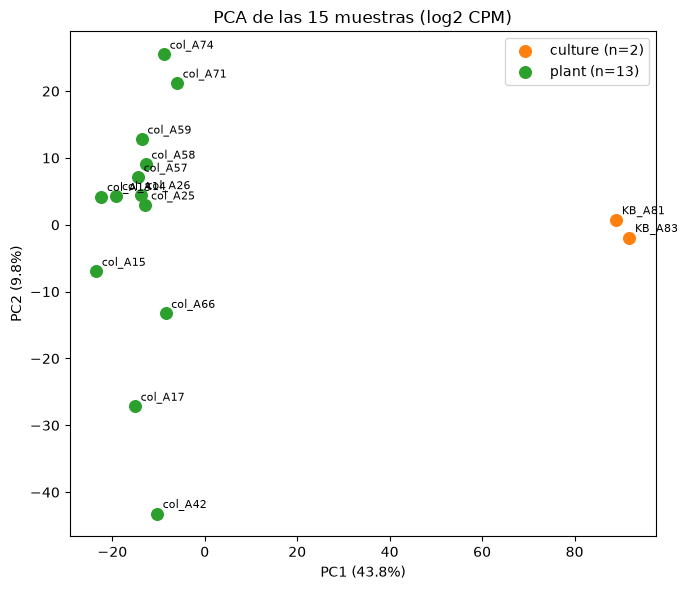

In [14]:
import matplotlib.pyplot as plt
import quality_control as qc

# un orden distinto asignaria la condicion equivocada a cada punto
if list(counts.columns) != list(meta.index):
    raise ValueError(
        "counts y meta tienen otro orden de muestras. Solución: vuelve a "
        "ejecutar desde la celda 7."
    )

pcs, variance = qc.pca_samples(counts, meta)
print("Varianza explicada (%):", variance[:5].round(1))
fig = qc.plot_pca(pcs, variance, meta, FIGURES / "pca_samples.png")
plt.show()

## Celda 14: profundidad y mediana de conteos

             depth_millions  median_counts condition
Pto_col_A42            0.78           25.0     plant
Pto_col_A71            1.19           42.5     plant
Pto_col_A66            1.25           44.0     plant
Pto_KB_A83             1.28           56.0   culture
Pto_col_A74            1.32           48.0     plant
Pto_col_A15            1.62           56.0     plant
Pto_col_A57            1.70           56.0     plant
Pto_col_A25            1.79           62.0     plant
Pto_KB_A81             2.02           87.0   culture
Pto_col_A13            2.13           69.0     plant
Pto_col_A58            2.30           81.0     plant
Pto_col_A17            2.56           98.0     plant
Pto_col_A59            2.99          106.0     plant
Pto_col_A26            3.05          107.0     plant
Pto_col_A14            3.25          115.0     plant

          depth_millions             median_counts             
                    mean   min   max          mean   min    max
condition              

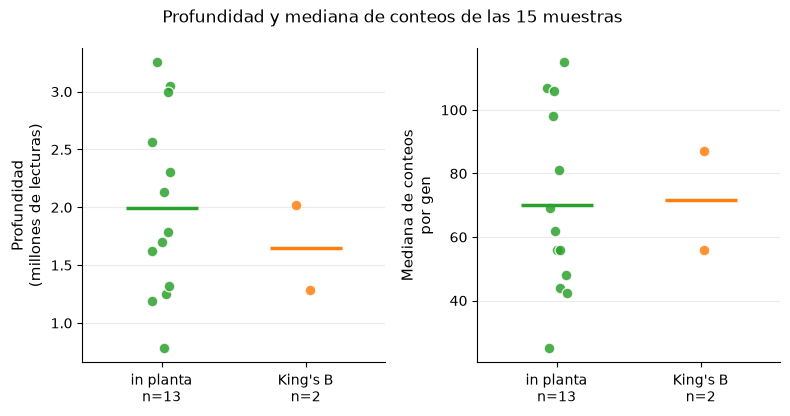

In [15]:
# counts_raw y no counts: el filtro quito los genes poco expresados y
# haria que las muestras parecieran mas parejas
metrics = qc.library_metrics(counts_raw, meta)
print(metrics.sort_values("depth_millions").round(2).to_string())

# resumen por grupo para comparar los rangos de planta y cultivo
summary_by_group = metrics.groupby("condition").agg(["mean", "min", "max"])
print()
print(summary_by_group.round(2).to_string())

fig = qc.plot_library_metrics(metrics, FIGURES / "library_metrics.png")
plt.show()